# Commerce international et croissance économique : une analyse économétrique à partir des World Development Indicators

## Problématique
Dans quelle mesure l'ouverture commerciale semble-t-elle associée à la croissance économique des pays, une fois prises en compte certaines variables macroéconomiques de contrôle ?

## Objectif du notebook
Ce notebook présente une démarche économétrique complète à partir de la base `World Development Indicators (WDI)` afin d'étudier la relation entre le commerce international et la croissance économique. L'analyse suit les étapes attendues : présentation de la base, choix des variables, transformation des données, statistiques descriptives, analyse de corrélation, régression, diagnostics, tests de robustesse et discussion finale.

## Portee économétrique
Le notebook estime principalement un modèle `pooled OLS` avec erreurs standards robustes. L'objectif est de mettre en évidence des **associations conditionnelles** et non de prouver une causalité stricte. Une attention particulière est donc portée à la construction de l'échantillon, aux données manquantes, aux valeurs extrêmes et aux observations influentes.


## 1. Environnement de travail

Le notebook utilise un environnement Python reproductible fonde sur `pandas` pour la gestion des données, `seaborn` et `matplotlib` pour les visualisations, et `statsmodels` pour l'estimation économétrique. Les options d'affichage sont reglees pour produire un document lisible et directement presentable.


In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import statsmodels.api as sm
from scipy.stats import pearsonr
from IPython.display import display
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")

DATA_PATH = Path("Indicators.csv")
COUNTRY_PATH = Path("Country.csv")
assert DATA_PATH.exists(), f"Fichier introuvable: {DATA_PATH.resolve()}"
assert COUNTRY_PATH.exists(), f"Fichier introuvable: {COUNTRY_PATH.resolve()}"

print("Les fichiers nécessaires ont bien été détectés dans le dossier de travail.")


Les fichiers nécessaires ont bien été détectés dans le dossier de travail.


## 2. Présentation et compréhension de la base de données

La base `World Development Indicators (WDI)` de la Banque mondiale est l'une des sources les plus utilisées en macroéconomie appliquée. Elle regroupe des indicateurs harmonisés pour un grand nombre de pays et sur plusieurs années, ce qui la rend adaptée à une analyse comparative internationale.

### Source et champ de la base
- Source : Banque mondiale, `World Development Indicators` (version Kaggle disponible dans ce projet)
- Fichier principal utilisé : `Indicators.csv`
- Unité d'observation dans le fichier brut : un pays, un indicateur, une année
- Structure des données : **format long**

### Pourquoi la base WDI est adaptée au sujet
Cette base est adaptée au thème « commerce international et croissance économique » car elle fournit des indicateurs comparables entre pays sur la croissance, le commerce, l'inflation, l'investissement, le chômage et la dynamique démographique.

### Pourquoi le passage au format large est nécessaire
Une régression nécessite une ligne par unité d'observation. Ici, l'unité pertinente est le **couple pays-année**. Or, dans le fichier brut WDI, chaque indicateur apparaît sur une ligne différente. Il faut donc transformer la base du **format long** vers le **format large** avant l'estimation économétrique.


In [2]:
usecols = ["CountryName", "CountryCode", "IndicatorName", "IndicatorCode", "Year", "Value"]

# Read in chunks to remain memory-conscious on the large WDI file.
total_rows = 0
sample_chunks = []
for i, chunk in enumerate(pd.read_csv(DATA_PATH, usecols=usecols, chunksize=500_000)):
    total_rows += len(chunk)
    if i == 0:
        sample_chunks.append(chunk.head(5))

sample_rows = pd.concat(sample_chunks, ignore_index=True)

print(f"Nombre approximatif de lignes dans la base brute: {total_rows:,}")
print("Colonnes utilisées :", usecols)
print("\nTypes des variables :")
print(sample_rows.dtypes)
print("\nExemple de lignes du fichier en format long :")
display(sample_rows)


Nombre approximatif de lignes dans la base brute: 5,656,458
Colonnes utilisées : ['CountryName', 'CountryCode', 'IndicatorName', 'IndicatorCode', 'Year', 'Value']

Types des variables :
CountryName       object
CountryCode       object
IndicatorName     object
IndicatorCode     object
Year               int64
Value            float64
dtype: object

Exemple de lignes du fichier en format long :


,CountryName,CountryCode,IndicatorName,IndicatorCode,Year,Value
0,Arab World,ARB,"Adolescent fertility rate (births per 1,000 wo...",SP.ADO.TFRT,1960,133.5609
1,Arab World,ARB,Age dependency ratio (% of working-age populat...,SP.POP.DPND,1960,87.7976
2,Arab World,ARB,"Age dependency ratio, old (% of working-age po...",SP.POP.DPND.OL,1960,6.6346
3,Arab World,ARB,"Age dependency ratio, young (% of working-age ...",SP.POP.DPND.YG,1960,81.0233
4,Arab World,ARB,Arms exports (SIPRI trend indicator values),MS.MIL.XPRT.KD,1960,"3,000,000.0000"


L'aperçu du fichier brut montre bien la logique du format long : un même pays apparaît plusieurs fois, car chaque ligne correspond à une combinaison `pays-indicateur-année`. Cette structure est pratique pour stocker un grand nombre d'indicateurs, mais elle n'est pas directement exploitable pour une régression multivariée tant que les variables choisies ne sont pas alignées sur une seule ligne par `pays-année`.


## 3. Choix des variables

Le modèle économétrique repose sur une variable dépendante, une variable explicative principale et plusieurs variables de contrôle. Ces variables de contrôle représentent des dimensions macroéconomiques susceptibles d'évoluer conjointement avec la croissance et le commerce.

- **GDP growth** est la variable dépendante `Y`, car elle mesure la performance économique annuelle.
- **Trade (% of GDP)** est la variable explicative principale `X`, car elle mesure l'ouverture commerciale.
- **Inflation** sert d'indicateur d'instabilite macroeconomique.
- **Unemployment** est retenue car un marche du travail degrade accompagne souvent une croissance plus faible.
- **Investment** est un determinant classique de la croissance dans la théorie économique.
- **Population growth** est incluse car la dynamique démographique peut influencer la croissance agregee.


In [3]:
indicator_info = [
    ("NY.GDP.MKTP.KD.ZG", "GDP growth (annual %)", "Y", "Dependent variable measuring annual real economic growth"),
    ("NE.TRD.GNFS.ZS", "Trade (% of GDP)", "Main X", "Trade openness indicator"),
    ("FP.CPI.TOTL.ZG", "Inflation, consumer prices (annual %)", "Control", "Macro-stability control"),
    ("SL.UEM.TOTL.ZS", "Unemployment, total (% of total labor force)", "Control", "Labor-market control"),
    ("NE.GDI.TOTL.ZS", "Gross capital formation (% of GDP)", "Control", "Investment control"),
    ("SP.POP.GROW", "Population growth (annual %)", "Control", "Demographic control"),
]

indicator_table = pd.DataFrame(
    indicator_info,
    columns=["Code de l'indicateur", "Nom de l'indicateur", "Role dans le modele", "Interpretation économique"]
)
display(indicator_table)


,Code de l'indicateur,Nom de l'indicateur,Role dans le modele,Interpretation économique
0,NY.GDP.MKTP.KD.ZG,GDP growth (annual %),Y,Dependent variable measuring annual real econo...
1,NE.TRD.GNFS.ZS,Trade (% of GDP),Main X,Trade openness indicator
2,FP.CPI.TOTL.ZG,"Inflation, consumer prices (annual %)",Control,Macro-stability control
3,SL.UEM.TOTL.ZS,"Unemployment, total (% of total labor force)",Control,Labor-market control
4,NE.GDI.TOTL.ZS,Gross capital formation (% of GDP),Control,Investment control
5,SP.POP.GROW,Population growth (annual %),Control,Demographic control


## 4. Transformation des données

Cette étape consiste a filtrer le fichier brut pour ne conserver que les indicateurs utiles, puis a transformer les données du format long vers le format large. Apres cette transformation, chaque ligne correspond à une observation `pays-année` avec toutes les variables nécessaires à l'estimation.


In [4]:
indicator_map = {
    "NY.GDP.MKTP.KD.ZG": "GDP_growth",
    "NE.TRD.GNFS.ZS": "Trade",
    "FP.CPI.TOTL.ZG": "Inflation",
    "SL.UEM.TOTL.ZS": "Unemployment",
    "NE.GDI.TOTL.ZS": "Investment",
    "SP.POP.GROW": "Population",
}

chunks = []
for chunk in pd.read_csv(DATA_PATH, usecols=usecols, chunksize=500_000):
    filtered = chunk[chunk["IndicatorCode"].isin(indicator_map)]
    chunks.append(filtered)

df_long = pd.concat(chunks, ignore_index=True)
df_long["variable"] = df_long["IndicatorCode"].map(indicator_map)

print("Taille de la base filtrée en format long :", df_long.shape)
display(df_long.head())

df_wide = (
    df_long.pivot_table(
        index=["CountryName", "CountryCode", "Year"],
        columns="variable",
        values="Value",
        aggfunc="first",
    )
    .reset_index()
)

ordered_cols = [
    "CountryName",
    "CountryCode",
    "Year",
    "GDP_growth",
    "Trade",
    "Inflation",
    "Unemployment",
    "Investment",
    "Population",
]
df_wide = df_wide[ordered_cols]

print("Taille de la base transformée en format large :", df_wide.shape)
display(df_wide.head())


Taille de la base filtrée en format long : (54892, 7)


,CountryName,CountryCode,IndicatorName,IndicatorCode,Year,Value,variable
0,East Asia & Pacific (all income levels),EAS,Trade (% of GDP),NE.TRD.GNFS.ZS,1960,26.8076,Trade
1,East Asia & Pacific (developing only),EAP,Gross capital formation (% of GDP),NE.GDI.TOTL.ZS,1960,33.3198,Investment
2,East Asia & Pacific (developing only),EAP,Trade (% of GDP),NE.TRD.GNFS.ZS,1960,17.4545,Trade
3,Euro area,EMU,Trade (% of GDP),NE.TRD.GNFS.ZS,1960,36.3974,Trade
4,Europe & Central Asia (all income levels),ECS,Trade (% of GDP),NE.TRD.GNFS.ZS,1960,39.0458,Trade


Taille de la base transformée en format large : (13471, 9)


variable,CountryName,CountryCode,Year,GDP_growth,Trade,Inflation,Unemployment,Investment,Population
0,Afghanistan,AFG,1960,NaN,11.1570,NaN,NaN,16.1157,1.8137
1,Afghanistan,AFG,1961,NaN,12.5506,NaN,NaN,16.5992,1.8740
2,Afghanistan,AFG,1962,NaN,14.2276,NaN,NaN,19.1057,1.9324
3,Afghanistan,AFG,1963,NaN,26.0355,NaN,NaN,14.2012,1.9898
4,Afghanistan,AFG,1964,NaN,26.9444,NaN,NaN,13.8889,2.0467


Cette transformation crée la structure de panel nécessaire au travail économétrique. Le tableau final contient désormais les identifiants `pays` et `année`, tandis que les six indicateurs retenus deviennent des colonnes pouvant entrer simultanément dans le modèle de régression.


## 5. Nettoyage des données et prétraitement

Cette section rend explicite la construction de l'échantillon final.

### Choix méthodologiques principaux
1. **Exclure les agrégats** tels que `World`, `Arab World` ou les groupes régionaux. Ce ne sont pas des pays individuels et leur présence fausserait une régression au niveau des pays.
2. **Retenir la période 1995-2014**. Le fichier local WDI s'arrête en 2014, et la variable de chômage commence plus tard que les autres. Commencer en 1995 permet d'obtenir un panel plus large que 2010-2014 tout en gardant une couverture correcte des variables.
3. **Utiliser un échantillon complet (`complete-case`) pour le modèle de base**. Cela évite d'introduire artificiellement des valeurs imputées dans la variable dépendante et rend la spécification principale plus transparente.
4. **Réserver l'interpolation à un test de robustesse**. Ce choix est plus prudent d'un point de vue académique, car il sépare le modèle principal d'hypothèses de prétraitement plus fortes.

### Pourquoi traiter les données manquantes avec prudence ?
Dans une base internationale comme WDI, toutes les variables ne sont pas observées pour tous les pays ni pour toutes les années. Si ce problème est traité de façon trop mécanique, on risque soit de perdre beaucoup d'observations, soit au contraire de fabriquer artificiellement des valeurs qui n'existaient pas dans la base d'origine. Dans les deux cas, l'interprétation économétrique peut devenir fragile.

### Pourquoi le choix `complete-case` dans le modèle principal ?
Le modèle principal conserve uniquement les observations complètes. Ce choix réduit la taille de l'échantillon, mais il a plusieurs avantages :
- il est simple à expliquer et très transparent ;
- il évite une imputation excessive qui pourrait fausser les coefficients ;
- il protège en particulier la variable dépendante `GDP_growth`, que l'on préfère ne pas imputer, car cela reviendrait à reconstruire artificiellement une partie du phénomène à expliquer.

### Pourquoi utiliser ensuite une interpolation limitée ?
L'interpolation n'est pas employée pour construire le modèle principal, mais comme **test de robustesse**. Elle n'est appliquée qu'aux variables explicatives, pour de petits trous internes dans les séries temporelles des pays. L'idée est de vérifier si la conclusion générale change fortement lorsque l'on remplit de manière prudente certaines valeurs manquantes plausibles.



In [5]:
country_meta = pd.read_csv(
    COUNTRY_PATH,
    usecols=["CountryCode", "ShortName", "Region", "IncomeGroup"]
)

country_only_codes = country_meta.loc[country_meta["Region"].notna(), "CountryCode"]

df_panel = df_wide.copy()
before_country_filter = df_panel.shape[0]
df_panel = df_panel[df_panel["CountryCode"].isin(country_only_codes)].copy()
after_country_filter = df_panel.shape[0]

numeric_cols = ["GDP_growth", "Trade", "Inflation", "Unemployment", "Investment", "Population"]
for col in numeric_cols:
    df_panel[col] = pd.to_numeric(df_panel[col], errors="coerce")

duplicate_count = df_panel.duplicated(subset=["CountryCode", "Year"]).sum()
df_panel = df_panel.drop_duplicates(subset=["CountryCode", "Year"]).copy()

coverage = (
    df_panel.groupby("Year")
    .agg(
        countries=("CountryCode", "nunique"),
        complete_rows=("GDP_growth", lambda s: s.notna().sum())
    )
    .reset_index()
)

period_start, period_end = 1995, 2014
df_period = df_panel[(df_panel["Year"] >= period_start) & (df_panel["Year"] <= period_end)].copy()

missing_before = df_period[numeric_cols].isna().sum().to_frame("Valeurs manquantes avant nettoyage")
baseline_df = df_period.dropna(subset=numeric_cols).copy()
missing_after = baseline_df[numeric_cols].isna().sum().to_frame("Valeurs manquantes après nettoyage complete-case")

missing_share = (df_period[numeric_cols].isna().mean() * 100).round(2).to_frame("Part manquante (%)")

print(f"Nombre de lignes avant suppression des agrégats: {before_country_filter:,}")
print(f"Nombre de lignes apres suppression des agrégats: {after_country_filter:,}")
print(f"Nombre de doublons pays-année detectes: {duplicate_count:,}")
print(f"Nombre de lignes sur la période retenue ({period_start}-{period_end}) before cleaning: {len(df_period):,}")
print(f"Nombre de lignes conservées dans l'échantillon de base: {len(baseline_df):,}")
print(f"Nombre de pays conserves dans l'échantillon de base: {baseline_df['CountryCode'].nunique():,}")
print(f"Part des observations pays-année conservées dans l'échantillon de base: {len(baseline_df) / len(df_period):.2%}")

print("\nCouverture des pays par année :")
display(coverage.tail(10))

print("\nValeurs manquantes avant nettoyage :")
display(missing_before)

print("\nPart des valeurs manquantes avant nettoyage :")
display(missing_share)

print("\nValeurs manquantes après nettoyage de base :")
display(missing_after)

display(baseline_df.head())


Nombre de lignes avant suppression des agrégats: 13,471
Nombre de lignes apres suppression des agrégats: 11,669
Nombre de doublons pays-année detectes: 0
Nombre de lignes sur la période retenue (1995-2014) before cleaning: 4,276
Nombre de lignes conservées dans l'échantillon de base: 2,818
Nombre de pays conserves dans l'échantillon de base: 159
Part des observations pays-année conservées dans l'échantillon de base: 65.90%

Couverture des pays par année :


,Year,countries,complete_rows
45,2005,214,197
46,2006,214,197
47,2007,214,197
48,2008,214,194
49,2009,214,193
50,2010,214,190
51,2011,214,190
52,2012,214,189
53,2013,214,190
54,2014,214,181



Valeurs manquantes avant nettoyage :


,Valeurs manquantes avant nettoyage
variable,
GDP_growth,418
Trade,645
Inflation,993
Unemployment,796
Investment,779
Population,5



Part des valeurs manquantes avant nettoyage :


,Part manquante (%)
variable,
GDP_growth,9.7800
Trade,15.0800
Inflation,23.2200
Unemployment,18.6200
Investment,18.2200
Population,0.1200



Valeurs manquantes après nettoyage de base :


,Valeurs manquantes après nettoyage complete-case
variable,
GDP_growth,0
Trade,0
Inflation,0
Unemployment,0
Investment,0
Population,0


variable,CountryName,CountryCode,Year,GDP_growth,Trade,Inflation,Unemployment,Investment,Population
45,Afghanistan,AFG,2005,11.1753,104.8624,12.6863,8.5000,21.5682,3.7587
46,Afghanistan,AFG,2006,5.5541,100.5553,7.2549,8.8000,23.3562,3.1613
47,Afghanistan,AFG,2007,13.7402,76.1738,8.4829,8.4000,19.8649,2.7182
48,Afghanistan,AFG,2008,3.6114,73.0655,30.5549,8.9000,18.8697,2.4853
49,Afghanistan,AFG,2009,21.0206,56.9068,-8.2831,8.1000,17.8922,2.5256


L'échantillon de base conserve uniquement les observations `pays-année` pour lesquelles les six variables sont observées. Ce choix réduit la taille de l'échantillon, mais il améliore l'interpretation du modèle, car la régression n'est pas portée par une imputation excessive. En contrepartie, les pays ayant une qualité de reporting plus faible contribuent moins à l'analyse.

Le tableau des valeurs manquantes montre aussi pourquoi l'interpolation doit être utilisee avec prudence. Dans cette base, le manque d'information n'est pas négligeable pour l'inflation, le chômage, l'investissement et le commerce. Si l'on remplaçait massivement ces valeurs dans le modèle principal, la régression pourrait paraître artificiellement plus precise qu'elle ne l'est réellement.

Autrement dit, nos "astuces" de traitement des données manquantes ont un but methodologique clair :
- **complète-case** pour garder un modèle principal defendable et transparent ;
- **interpolation linéaire limitée** pour tester la sensibilité des résultats sans dénaturer la base ;
- **absence d'imputation de la variable dépendante** pour ne pas fabriquer artificiellement la variable a expliquer ;
- **comparaison entre plusieurs stratégies** pour montrer que la conclusion économétrique ne dépend pas d'un seul choix technique.

C'est pourquoi le notebook distingue bien **le modèle de base** et **l'analyse de sensibilité avec interpolation**. Cette distinction renforce la crédibilité du travail , car elle montre que le traitement des données manquantes a été pensé comme un choix économétrique, et non comme une simple étape automatique de nettoyage.


In [6]:
baseline_df.to_csv("trade_growth_clean_panel_professor.csv", index=False)
print("Le fichier propre pour la regression a ete enregistre: trade_growth_clean_panel_professor.csv")


Le fichier propre pour la regression a ete enregistre: trade_growth_clean_panel_professor.csv


## 6. Analyse univariée

Cette section répond explicitement à l'exigence d'analyse univariée du projet. Elle décrit chaque variable séparément avant de passer à la modélisation multivariée. L'objectif est d'étudier la tendance centrale, la dispersion, l'asymétrie et la présence éventuelle de valeurs extrêmes.


In [7]:
desc_stats = baseline_df[numeric_cols].describe().T
desc_stats["median"] = baseline_df[numeric_cols].median()
desc_stats["skewness"] = baseline_df[numeric_cols].skew()
desc_stats = desc_stats[["count", "mean", "median", "std", "min", "25%", "50%", "75%", "max", "skewness"]]
display(desc_stats)


,count,mean,median,std,min,25%,50%,75%,max,skewness
variable,,,,,,,,,,
GDP_growth,"2,818.0000",4.0654,3.9817,5.5354,-36.0471,1.9289,3.9817,6.0690,149.9730,7.5845
Trade,"2,818.0000",89.5227,78.1821,56.6624,0.3088,55.0599,78.1821,106.5969,531.7374,2.8626
Inflation,"2,818.0000",10.4649,4.2813,84.4288,-18.1086,2.0744,4.2813,8.2784,"4,145.1076",42.7623
Unemployment,"2,818.0000",8.8149,7.2000,6.4312,0.1000,4.4000,7.2000,10.8000,38.6000,1.7216
Investment,"2,818.0000",23.5843,22.3659,10.9899,0.2986,18.7727,22.3659,26.6744,219.0694,7.2870
Population,"2,818.0000",1.4996,1.4375,1.4865,-3.8202,0.4657,1.4375,2.4431,17.6248,2.3706


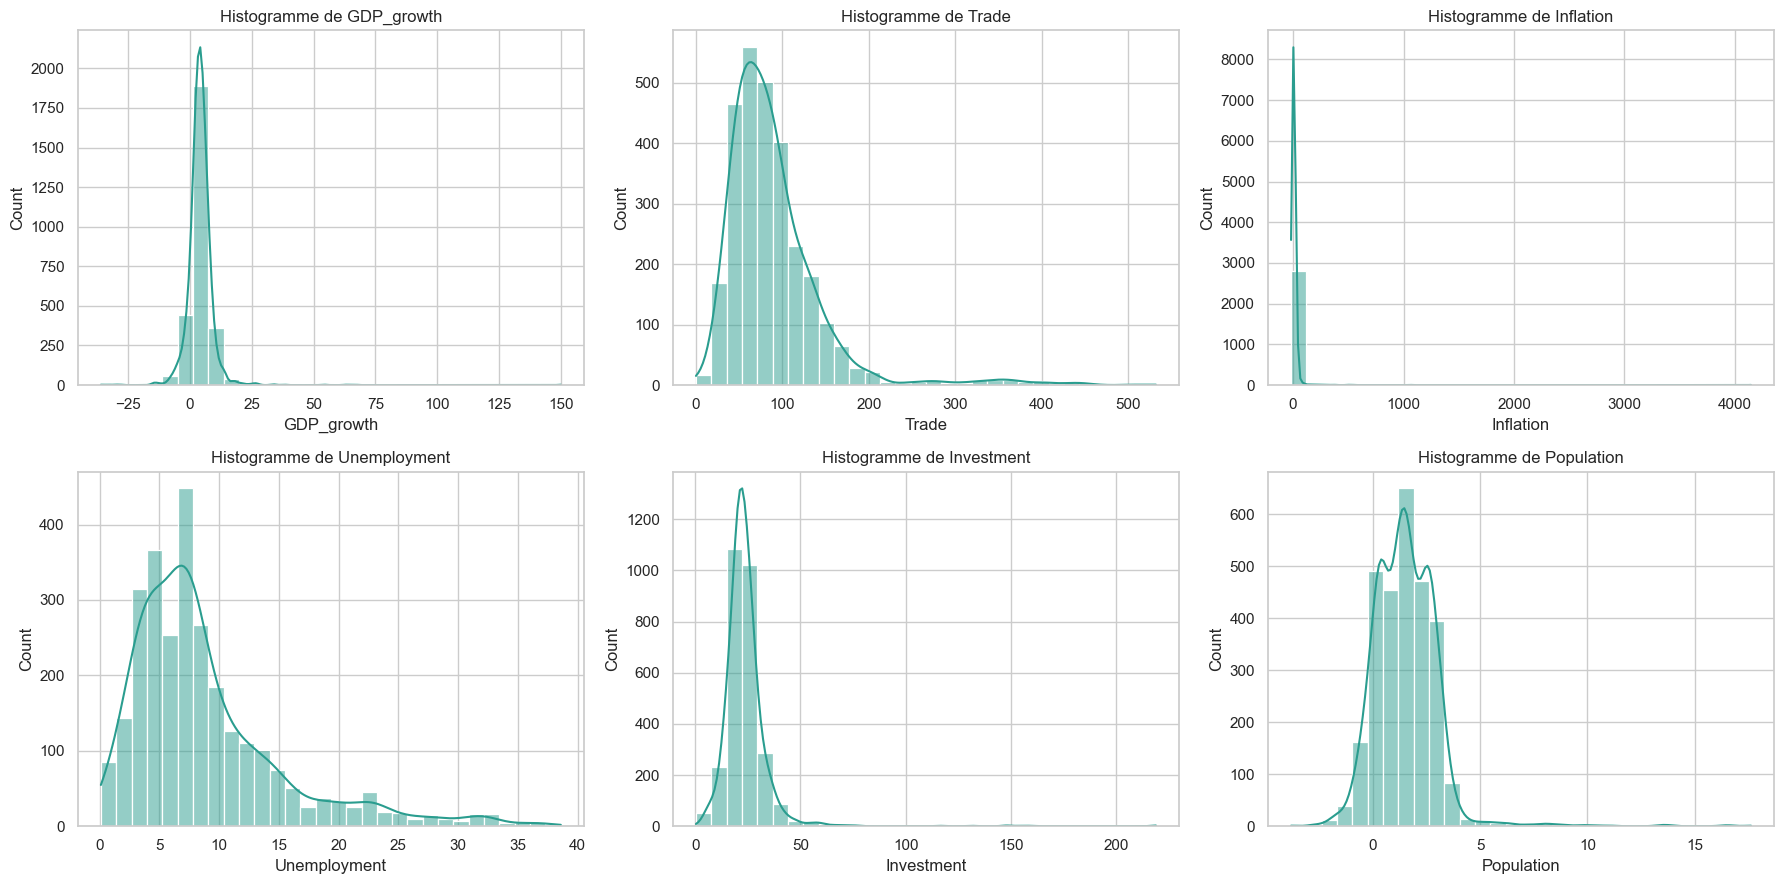

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()
for ax, col in zip(axes, numeric_cols):
    sns.histplot(baseline_df[col], kde=True, bins=30, ax=ax, color="#2a9d8f")
    ax.set_title(f"Histogramme de {col}")
plt.tight_layout()
plt.show()


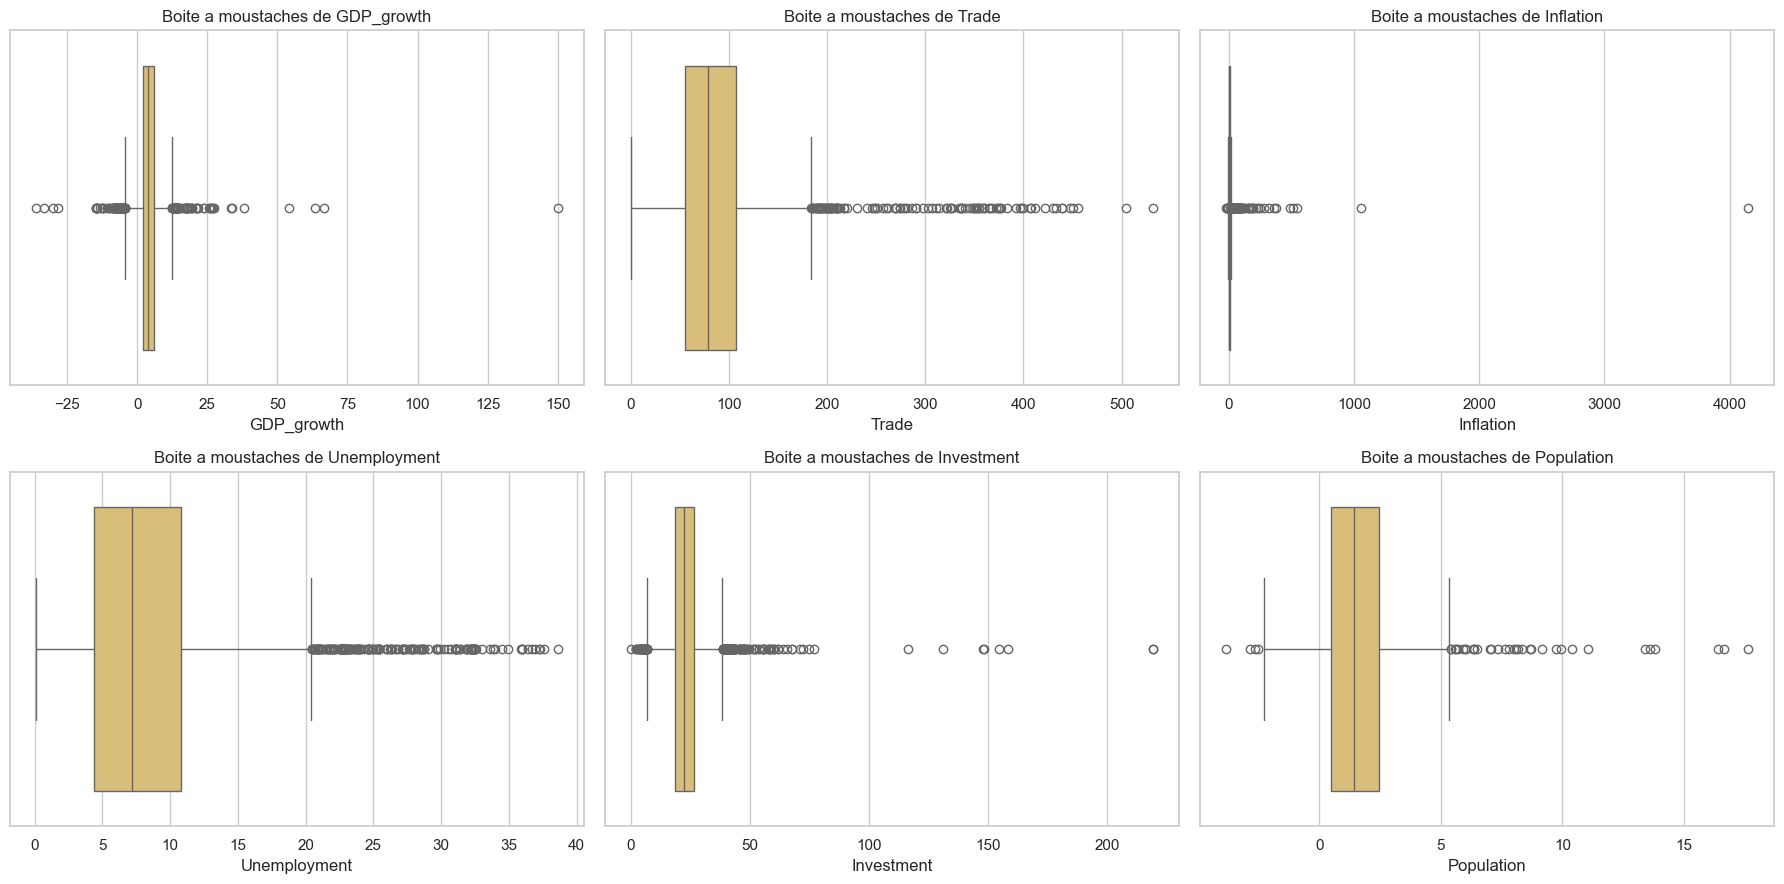

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(x=baseline_df[col], ax=ax, color="#e9c46a")
    ax.set_title(f"Boite a moustaches de {col}")
plt.tight_layout()
plt.show()


In [10]:
iqr_summary = []
for col in numeric_cols:
    q1 = baseline_df[col].quantile(0.25)
    q3 = baseline_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = ((baseline_df[col] < lower) | (baseline_df[col] > upper)).sum()
    iqr_summary.append((col, baseline_df[col].median(), baseline_df[col].std(), baseline_df[col].skew(), outliers))

iqr_table = pd.DataFrame(
    iqr_summary,
    columns=["Variable", "Mediane", "Ecart-type", "Asymétrie", "Nombre d'outliers (IQR)"]
)
display(iqr_table)

print("Interpretation univariee :")
for _, row in iqr_table.iterrows():
    skew_label = "asymétrique a droite" if row["Asymétrie"] > 0.5 else ("asymétrique a gauche" if row["Asymétrie"] < -0.5 else "approximativement symetrique")
    n_out = int(row["Nombre d'outliers (IQR)"])
    print(
        f"- {row['Variable']} : médiane = {row['Mediane']:.3f}, écart-type = {row['Ecart-type']:.3f}, distribution {skew_label}, et la boite a moustaches signale {n_out} valeurs potentiellement extrêmes."
    )
print("- Les variables n'operent pas sur les mêmes ordres de grandeur, ce qui est fréquent en macroeconomie et renforce l'importance d'une interprétation prudente.")


,Variable,Mediane,Ecart-type,Asymétrie,Nombre d'outliers (IQR)
0,GDP_growth,3.9817,5.5354,7.5845,161
1,Trade,78.1821,56.6624,2.8626,116
2,Inflation,4.2813,84.4288,42.7623,223
3,Unemployment,7.2000,6.4312,1.7216,201
4,Investment,22.3659,10.9899,7.2870,149
5,Population,1.4375,1.4865,2.3706,38


Interpretation univariee :
- GDP_growth : médiane = 3.982, écart-type = 5.535, distribution asymétrique a droite, et la boite a moustaches signale 161 valeurs potentiellement extrêmes.
- Trade : médiane = 78.182, écart-type = 56.662, distribution asymétrique a droite, et la boite a moustaches signale 116 valeurs potentiellement extrêmes.
- Inflation : médiane = 4.281, écart-type = 84.429, distribution asymétrique a droite, et la boite a moustaches signale 223 valeurs potentiellement extrêmes.
- Unemployment : médiane = 7.200, écart-type = 6.431, distribution asymétrique a droite, et la boite a moustaches signale 201 valeurs potentiellement extrêmes.
- Investment : médiane = 22.366, écart-type = 10.990, distribution asymétrique a droite, et la boite a moustaches signale 149 valeurs potentiellement extrêmes.
- Population : médiane = 1.438, écart-type = 1.487, distribution asymétrique a droite, et la boite a moustaches signale 38 valeurs potentiellement extrêmes.
- Les variables n'operent

In [11]:
extreme_rows = []
for col in numeric_cols:
    top_obs = baseline_df.nlargest(3, col)[["CountryName", "Year", col]].copy()
    top_obs["Variable"] = col
    top_obs = top_obs.rename(columns={col: "Value"})
    extreme_rows.append(top_obs[["Variable", "CountryName", "Year", "Value"]])

extreme_table = pd.concat(extreme_rows, ignore_index=True)
display(extreme_table)

print("Interpretation des valeurs extrêmes :")
print("- Des taux de croissance du PIB tres élevés refletent souvent des rebonds post-conflit, des booms lies aux matières premières ou des reprises apres une forte contraction, plutot qu'une croissance ordinaire.")
print("- Des ratios Trade/PIB tres élevés sont fréquents dans les petites economies tres ouvertes ou dans les pays exportateurs de ressources et ne doivent donc pas etre consideres automatiquement comme des erreurs.")
print("- Des niveaux d'inflation extrêmes traduisent souvent des episodes d'instabilite macroeconomique, ce qui peut rendre les regressions internationales plus bruitées.")
print("- Ces constats justifient l'analyse formelle des observations influentes avant d'interpreter trop fortement le coefficient du commerce.")


variable,Variable,CountryName,Year,Value
0,GDP_growth,Equatorial Guinea,1997,149.9730
1,GDP_growth,Equatorial Guinea,1996,66.5800
2,GDP_growth,Equatorial Guinea,2001,63.3799
3,Trade,Equatorial Guinea,1998,531.7374
4,Trade,Equatorial Guinea,1996,504.8837
5,Trade,"Hong Kong SAR, China",2013,455.2767
6,Inflation,Angola,1996,"4,145.1076"
7,Inflation,Bulgaria,1997,"1,058.3739"
8,Inflation,"Congo, Dem. Rep.",1995,541.9089
9,Unemployment,Lesotho,2003,38.6000


Interpretation des valeurs extrêmes :
- Des taux de croissance du PIB tres élevés refletent souvent des rebonds post-conflit, des booms lies aux matières premières ou des reprises apres une forte contraction, plutot qu'une croissance ordinaire.
- Des ratios Trade/PIB tres élevés sont fréquents dans les petites economies tres ouvertes ou dans les pays exportateurs de ressources et ne doivent donc pas etre consideres automatiquement comme des erreurs.
- Des niveaux d'inflation extrêmes traduisent souvent des episodes d'instabilite macroeconomique, ce qui peut rendre les regressions internationales plus bruitées.
- Ces constats justifient l'analyse formelle des observations influentes avant d'interpreter trop fortement le coefficient du commerce.


L'analyse univariée montre déjà que l'échantillon contient plusieurs observations extrêmes, notamment pour la croissance, l'inflation et l'ouverture commerciale. Cela est important, car une régression `pooled OLS` peut être sensible à ce type de cas. Les diagnostics et les tests de robustesse sont donc indispensables.


## 7. Analyse de corrélation et relation bivariée

On étudie ensuite la relation directe entre la variable dépendante et la variable explicative principale. Cette analyse ne contrôle pas encore les autres régressseurs et doit donc être interprétée comme une relation descriptive.

Il faut rappeler qu'une **corrélation n'implique pas une causalité**. Même une forte association bivariée ne permet pas d'affirmer que le commerce cause la croissance.


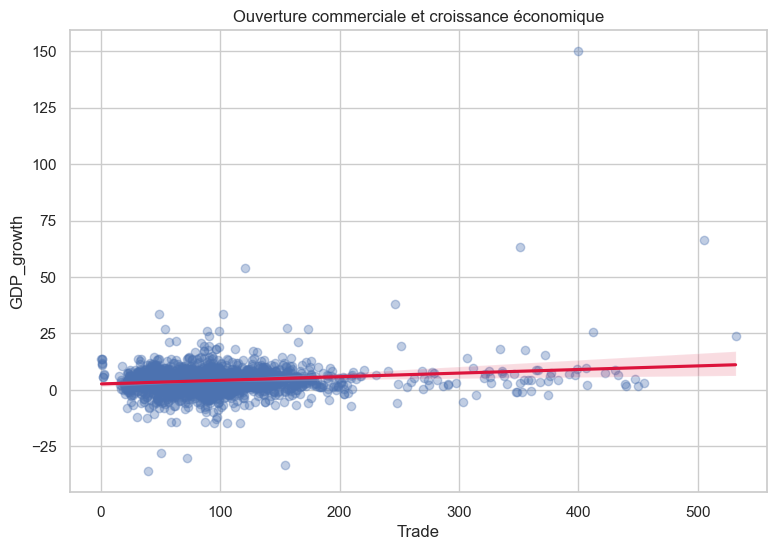

Coefficient de corrélation de Pearson: 0.1633
P-value: 2.644e-18


In [12]:
plt.figure(figsize=(9, 6))
sns.regplot(
    data=baseline_df,
    x="Trade",
    y="GDP_growth",
    scatter_kws={"alpha": 0.35},
    line_kws={"color": "crimson"}
)
plt.title("Ouverture commerciale et croissance économique")
plt.show()

pearson_r, pearson_p = pearsonr(baseline_df["Trade"], baseline_df["GDP_growth"])
print(f"Coefficient de corrélation de Pearson: {pearson_r:.4f}")
print(f"P-value: {pearson_p:.4g}")


In [13]:
if pearson_p < 0.05:
    sig_text = "statistiquement significative"
else:
    sig_text = "non statistiquement significative"

direction = "positive" if pearson_r > 0 else "négative"
print("Interprétation bivariée :")
print(
    f"- La corrélation brute entre Trade et GDP growth est de {pearson_r:.4f}, ce qui indique une association linéaire {direction}."
)
print(f"- Cette corrélation est {sig_text} aux seuils usuels.")
print("- Comme il s'agit d'un résultat bivarié, il ne tient pas compte de l'inflation, du chômage, de l'investissement ni de la croissance de la population.")


Interprétation bivariée :
- La corrélation brute entre Trade et GDP growth est de 0.1633, ce qui indique une association linéaire positive.
- Cette corrélation est statistiquement significative aux seuils usuels.
- Comme il s'agit d'un résultat bivarié, il ne tient pas compte de l'inflation, du chômage, de l'investissement ni de la croissance de la population.


## 8. Modèle économétrique

Après l’analyse descriptive et l’analyse bivariée, cette étape correspond à une **analyse multivariée**. L’objectif est d’étudier la relation entre le commerce et la croissance économique en tenant compte simultanément de plusieurs autres facteurs susceptibles d’influencer la croissance.

Dans ce projet, la croissance économique est donc modélisée en fonction de l’ouverture commerciale, de l’inflation, du chômage, de l’investissement et de la croissance de la population. Autrement dit, on cherche à évaluer si le commerce reste associé à la croissance une fois plusieurs variables de contrôle macroéconomiques prises en compte.

Le modèle retenu relie la variable dépendante `GDP_growth` à la variable explicative principale `Trade`, ainsi qu’aux variables de contrôle `Inflation`, `Unemployment`, `Investment` et `Population`.

### Pourquoi parler d’analyse multivariée ?
On parle d’analyse multivariée parce que plusieurs variables explicatives sont introduites en même temps dans le modèle. Cela permet de mesurer l’association entre `Trade` et `GDP_growth` tout en contrôlant les effets d’autres variables macroéconomiques. Cette approche est plus informative qu’une simple analyse bivariée, car elle réduit le risque d’interpréter à tort comme un effet du commerce ce qui pourrait en réalité provenir de l’investissement, du chômage ou de l’inflation.

### Pourquoi utiliser un modèle pooled OLS ?
Le `pooled OLS` constitue ici un modèle de base clair, interprétable et adapté à un projet universitaire. Il permet d’étudier si le commerce est associé à la croissance économique après prise en compte de plusieurs variables de contrôle macroéconomiques.

### Pourquoi utiliser des erreurs standards robustes ?
Dans des données macroéconomiques internationales, l’hétéroscédasticité est fréquente. Cela signifie que la variance des erreurs peut différer d’un pays à l’autre. Pour cette raison, le modèle est estimé avec des erreurs standards robustes de type `HC3`, afin d’obtenir des tests statistiques plus fiables.


In [14]:
X_vars = ["Trade", "Inflation", "Unemployment", "Investment", "Population"]
X = sm.add_constant(baseline_df[X_vars])
y = baseline_df["GDP_growth"]

ols_hc3 = sm.OLS(y, X).fit(cov_type="HC3")
print(ols_hc3.summary())


                            OLS Regression Results                            
Dep. Variable:             GDP_growth   R-squared:                       0.206
Model:                            OLS   Adj. R-squared:                  0.205
Method:                 Least Squares   F-statistic:                     17.27
Date:                Tue, 31 Mar 2026   Prob (F-statistic):           7.11e-17
Time:                        19:51:46   Log-Likelihood:                -8494.7
No. Observations:                2818   AIC:                         1.700e+04
Df Residuals:                    2812   BIC:                         1.704e+04
Df Model:                           5                                         
Covariance Type:                  HC3                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -1.7520      1.296     -1.352   

In [15]:
coef_table = pd.DataFrame({
    "Coefficient": ols_hc3.params,
    "Erreur standard robuste": ols_hc3.bse,
    "z-stat": ols_hc3.tvalues,
    "p-value": ols_hc3.pvalues
})
display(coef_table)

print("Interprétation de la régression :")
for var in X_vars:
    coef = ols_hc3.params[var]
    pval = ols_hc3.pvalues[var]
    if pval < 0.01:
        sig = "hautement significatif"
    elif pval < 0.05:
        sig = "significatif"
    elif pval < 0.10:
        sig = "faiblement significatif"
    else:
        sig = "non statistiquement significatif"
    sign = "positif" if coef > 0 else "négatif"
    print(f"- {var} : coefficient = {coef:.4f}, signe {sign}, {sig} (p = {pval:.4f}).")

trade_coef = ols_hc3.params["Trade"]
trade_p = ols_hc3.pvalues["Trade"]
print("\nFocalisation sur la variable Trade :")
if trade_p < 0.05:
    print(
        f"- Dans le modèle de base, Trade est positivement associé à la croissance et cet effet est statistiquement significatif (coefficient = {trade_coef:.4f}, p = {trade_p:.4f})."
    )
else:
    print(
        f"- Dans le modèle de base, Trade a un coefficient positif ({trade_coef:.4f}) mais il n'est pas statistiquement significatif (p = {trade_p:.4f})."
    )
    print("- Cela signifie que la spécification de base ne fournit pas une preuve statistique forte d'une association indépendante entre ouverture commerciale et croissance, une fois les variables de contrôle introduites.")


,Coefficient,Erreur standard robuste,z-stat,p-value
const,-1.7520,1.2957,-1.3522,0.1763
Trade,0.0031,0.0022,1.4139,0.1574
Inflation,-0.0000,0.0055,-0.0077,0.9939
Unemployment,-0.0176,0.0183,-0.9573,0.3384
Investment,0.2028,0.0498,4.0716,0.0000
Population,0.6089,0.0781,7.7954,0.0000


Interprétation de la régression :
- Trade : coefficient = 0.0031, signe positif, non statistiquement significatif (p = 0.1574).
- Inflation : coefficient = -0.0000, signe négatif, non statistiquement significatif (p = 0.9939).
- Unemployment : coefficient = -0.0176, signe négatif, non statistiquement significatif (p = 0.3384).
- Investment : coefficient = 0.2028, signe positif, hautement significatif (p = 0.0000).
- Population : coefficient = 0.6089, signe positif, hautement significatif (p = 0.0000).

Focalisation sur la variable Trade :
- Dans le modèle de base, Trade a un coefficient positif (0.0031) mais il n'est pas statistiquement significatif (p = 0.1574).
- Cela signifie que la spécification de base ne fournit pas une preuve statistique forte d'une association indépendante entre ouverture commerciale et croissance, une fois les variables de contrôle introduites.


### Interprétation économétrique approfondie

Le coefficient du commerce dans le modèle de base doit être interprété avec prudence. Un coefficient non significatif ne veut pas dire que le commerce est sans importance en réalité économique. Cela signifie plutôt que, dans cet échantillon et avec cette spécification, l'association conditionnelle estimée est trop imprécise pour être distinguée clairement de zéro aux seuils usuels.

Plusieurs explications sont possibles :
- **Hétérogénéité entre pays** : les pays diffèrent fortement par leurs institutions, leur structure productive, leur géographie et leur niveau de développement.
- **Effets de mesure et de composition** : la variable `Trade (% of GDP)` ne distingue pas entre exportations manufacturières, exportations de matières premières, économies de réexportation ou forte dépendance aux importations.
- **Horizon macroéconomique bruité** : même avec la période élargie 1995-2014, la croissance annuelle reste volatile et sensible aux crises, aux conflits et aux chocs sur les matières premières.
- **Variables omises** : qualité institutionnelle, éducation, productivité, régimes de change ou stabilité politique ne sont pas contrôlés directement ici.
- **Possibles non-linéarités** : le commerce peut jouer un rôle plus important pour certains groupes de pays que pour d'autres.

À l'inverse, le coefficient positif et significatif de **l'investissement** est économiquement cohérent : une plus forte formation brute de capital est liée à l'accumulation de capital, aux infrastructures et aux capacités productives, qui sont des moteurs classiques de la croissance.

Le coefficient négatif du **chômage** a également un sens économique plausible. Un niveau de chômage plus élevé traduit souvent une moindre utilisation du facteur travail et s'accompagne fréquemment d'une croissance plus faible.


## 9. Diagnostics

Cette section évalue si le modèle de base est perturbe par des problèmes économétriques classiques tels que la multicolinéarité, l'hétéroscédasticité ou la présence d'observations influentes.


In [16]:
vif_table = pd.DataFrame({
    "Variable": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
display(vif_table)

bp_stat, bp_pvalue, f_stat, f_pvalue = het_breuschpagan(ols_hc3.resid, X)
print(f"Statistique LM de Breusch-Pagan: {bp_stat:.4f}")
print(f"P-value du test de Breusch-Pagan: {bp_pvalue:.4g}")
print("Interpretation : une faible p-value suggere une hétéroscédasticité, ce qui justifie l'usage d'erreurs standards robustes.")


,Variable,VIF
0,const,9.8968
1,Trade,1.1257
2,Inflation,1.0003
3,Unemployment,1.0438
4,Investment,1.1279
5,Population,1.0465


Statistique LM de Breusch-Pagan: 178.0737
P-value du test de Breusch-Pagan: 1.38e-36
Interpretation : une faible p-value suggere une hétéroscédasticité, ce qui justifie l'usage d'erreurs standards robustes.


In [17]:
influence = ols_hc3.get_influence()
diagnostics = baseline_df[["CountryName", "CountryCode", "Year"]].copy()
diagnostics["fitted"] = ols_hc3.fittedvalues
diagnostics["residual"] = ols_hc3.resid
diagnostics["std_residual"] = influence.resid_studentized_internal
diagnostics["cooks_distance"] = influence.cooks_distance[0]
diagnostics["leverage"] = influence.hat_matrix_diag

top_influential = diagnostics.sort_values("cooks_distance", ascending=False).head(10)
display(top_influential)

cook_threshold = 4 / len(diagnostics)
high_influence_count = (diagnostics["cooks_distance"] > cook_threshold).sum()
print(f"Seuil de la distance de Cook (4/n): {cook_threshold:.6f}")
print(f"Nombre d'observations au-dessus du seuil: {high_influence_count}")


variable,CountryName,CountryCode,Year,fitted,residual,std_residual,cooks_distance,leverage
3554,Equatorial Guinea,GNQ,1997,31.5155,118.4574,24.5893,5.0257,0.0475
311,Angola,AGO,1996,7.2442,3.9558,2.0875,4.2018,0.8526
3555,Equatorial Guinea,GNQ,1998,46.2465,-22.4720,-4.8371,0.5027,0.1142
3553,Equatorial Guinea,GNQ,1996,46.1974,20.3826,4.3860,0.4111,0.1137
3558,Equatorial Guinea,GNQ,2001,31.2543,32.1256,6.6644,0.3593,0.0463
3552,Equatorial Guinea,GNQ,1995,33.4660,-15.9798,-3.3289,0.1059,0.0542
5703,Iraq,IRQ,2004,3.1845,50.9732,10.3525,0.0898,0.0050
5702,Iraq,IRQ,2003,4.1942,-37.2950,-7.5776,0.0558,0.0058
3561,Equatorial Guinea,GNQ,2004,16.4927,21.5060,4.3780,0.0310,0.0096
12726,United Arab Emirates,ARE,2009,11.3986,-16.6415,-3.3981,0.0306,0.0157


Seuil de la distance de Cook (4/n): 0.001419
Nombre d'observations au-dessus du seuil: 107


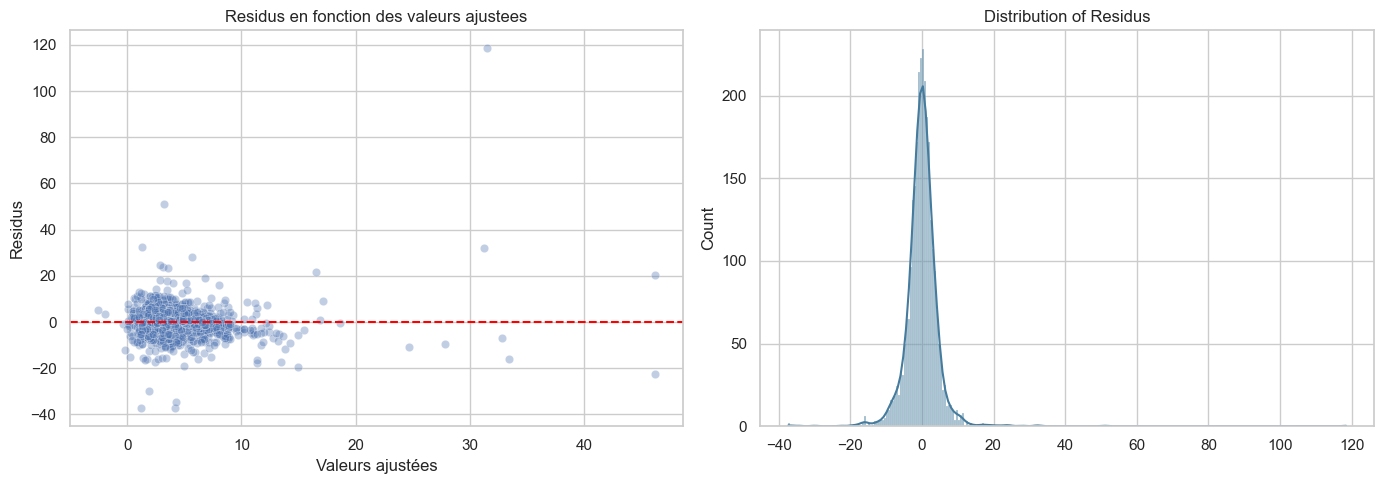

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x=ols_hc3.fittedvalues, y=ols_hc3.resid, alpha=0.35, ax=axes[0])
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residus en fonction des valeurs ajustees")
axes[0].set_xlabel("Valeurs ajustées")
axes[0].set_ylabel("Residus")

sns.histplot(ols_hc3.resid, kde=True, ax=axes[1], color="#457b9d")
axes[1].set_title("Distribution of Residus")

plt.tight_layout()
plt.show()


In [19]:
print("Interprétation des diagnostics :")
print("- Des valeurs de VIF proches de 1 indiquent que la multicolinéarité n'est pas une préoccupation majeure dans cette spécification.")
if bp_pvalue < 0.05:
    print("- Le test de Breusch-Pagan suggère une hétéroscédasticité, ce qui justifie l'utilisation d'erreurs standards robustes HC3.")
else:
    print("- Le test de Breusch-Pagan ne révèle pas une hétéroscédasticité très forte, mais les erreurs standards robustes restent un choix prudent dans des données internationales.")
print("- Le tableau de la distance de Cook identifie un petit ensemble d'observations très influentes ; il faut donc tester explicitement la sensibilité du modèle aux valeurs extrêmes.")


Interprétation des diagnostics :
- Des valeurs de VIF proches de 1 indiquent que la multicolinéarité n'est pas une préoccupation majeure dans cette spécification.
- Le test de Breusch-Pagan suggère une hétéroscédasticité, ce qui justifie l'utilisation d'erreurs standards robustes HC3.
- Le tableau de la distance de Cook identifie un petit ensemble d'observations très influentes ; il faut donc tester explicitement la sensibilité du modèle aux valeurs extrêmes.


## 10. Biais et limites économétriques

Les résultats du modèle de base doivent être interprétés avec prudence.

### Biais de variable omise
La croissance économique dépend aussi de nombreux facteurs absents du modèle : qualité institutionnelle, éducation, gouvernance, dépendance aux ressources, conflits, changements technologiques, etc. Si ces facteurs omis sont corrélés avec le commerce, le coefficient du commerce peut être biaisé.

### Causalité inverse
Le commerce peut influencer la croissance, mais l'inverse est également possible. Les économies qui croissent vite ont souvent tendance à commercer davantage, à attirer plus d'investissements et à se diversifier plus rapidement. Le coefficient du commerce ne peut donc pas être interprété comme un effet causal pur.

### Limites de mesure
Les indicateurs internationaux proviennent de systèmes statistiques nationaux différents. Même harmonisées, les séries WDI peuvent contenir des différences de mesure, des révisions ou des problèmes de couverture.

### Limite temporelle
Le fichier local s'arrête en 2014. Même si l'échantillon a été élargi à 1995-2014, l'horizon reste limité par la version de la base disponible.






## 11. Test de robustesse

Le modèle de base peut être sensible aux observations influentes. Pour traiter ce point, la régression est réestimée apres suppression des observations dont la distance de Cook dépasse le seuil usuel de `4/n`. Ce test de robustesse est pertinent, car il cible directement le probleme des outliers identifié dans les diagnostics.

En complément, le notebook compare aussi le modèle de base `complète-case` à une variante avec interpolation linéaire limitée pour de petits trous internes dans les variables explicatives. La variable dépendante n'est jamais imputee.


In [20]:
robust_df = baseline_df.loc[diagnostics["cooks_distance"] <= cook_threshold].copy()
X_robust = sm.add_constant(robust_df[X_vars])
y_robust = robust_df["GDP_growth"]
ols_no_influential = sm.OLS(y_robust, X_robust).fit(cov_type="HC3")

interp_df = df_period.sort_values(["CountryCode", "Year"]).copy()
interp_controls = ["Trade", "Inflation", "Unemployment", "Investment", "Population"]
interp_df[interp_controls] = (
    interp_df.groupby("CountryCode", group_keys=False)[interp_controls]
    .apply(lambda g: g.interpolate(method="linear", limit=2, limit_area="inside"))
)
interp_df = interp_df.dropna(subset=numeric_cols).copy()
X_interp = sm.add_constant(interp_df[X_vars])
y_interp = interp_df["GDP_growth"]
ols_interp = sm.OLS(y_interp, X_interp).fit(cov_type="HC3")

comparison = pd.DataFrame({
    "Model": ["Baseline complete-case", "Without influential observations", "Interpolation sensitivity"],
    "Observations": [len(baseline_df), len(robust_df), len(interp_df)],
    "Trade coef.": [ols_hc3.params["Trade"], ols_no_influential.params["Trade"], ols_interp.params["Trade"]],
    "Investment coef.": [ols_hc3.params["Investment"], ols_no_influential.params["Investment"], ols_interp.params["Investment"]],
    "Trade p-value": [ols_hc3.pvalues["Trade"], ols_no_influential.pvalues["Trade"], ols_interp.pvalues["Trade"]],
    "R-squared": [ols_hc3.rsquared, ols_no_influential.rsquared, ols_interp.rsquared]
})
display(comparison)


,Model,Observations,Trade coef.,Investment coef.,Trade p-value,R-squared
0,Baseline complete-case,2818,0.0031,0.2028,0.1574,0.2062
1,Without influential observations,2711,0.0026,0.1410,0.0118,0.1454
2,Interpolation sensitivity,2829,0.0030,0.2018,0.1743,0.2049


In [21]:
print("Interprétation du test de robustesse :")
print(
    f"- Échantillon de base : coefficient de Trade = {ols_hc3.params['Trade']:.4f}, p-value = {ols_hc3.pvalues['Trade']:.4f}."
)
print(
    f"- Après suppression des observations influentes : coefficient de Trade = {ols_no_influential.params['Trade']:.4f}, p-value = {ols_no_influential.pvalues['Trade']:.4f}."
)
print(
    f"- Échantillon avec interpolation de sensibilité : coefficient de Trade = {ols_interp.params['Trade']:.4f}, p-value = {ols_interp.pvalues['Trade']:.4f}."
)
print(
    f"- R-carré du modèle de base = {ols_hc3.rsquared:.4f} ; sans observations influentes = {ols_no_influential.rsquared:.4f} ; avec interpolation = {ols_interp.rsquared:.4f}."
)

if ols_hc3.pvalues["Trade"] >= 0.05 and ols_no_influential.pvalues["Trade"] < 0.05:
    print("- Le résultat sur Trade devient statistiquement significatif une fois les observations les plus influentes retirées.")
    print("- Cela suggère que la non-significativité du modèle de base reflète en partie une sensibilité aux valeurs extrêmes plutôt qu'une absence totalement stable de relation.")
elif ols_hc3.pvalues["Trade"] < 0.05 and ols_no_influential.pvalues["Trade"] < 0.05:
    print("- La significativité de Trade reste globalement robuste après suppression des observations influentes.")
else:
    print("- Le résultat de Trade reste fragile selon les spécifications ; il faut donc parler d'évidence limitée plutôt que de conclusion définitive.")

print("- Le modèle avec interpolation produit des estimations de Trade très proches du modèle de base, ce qui suggère que la conclusion principale ne dépend pas uniquement du choix complete-case.")


Interprétation du test de robustesse :
- Échantillon de base : coefficient de Trade = 0.0031, p-value = 0.1574.
- Après suppression des observations influentes : coefficient de Trade = 0.0026, p-value = 0.0118.
- Échantillon avec interpolation de sensibilité : coefficient de Trade = 0.0030, p-value = 0.1743.
- R-carré du modèle de base = 0.2062 ; sans observations influentes = 0.1454 ; avec interpolation = 0.2049.
- Le résultat sur Trade devient statistiquement significatif une fois les observations les plus influentes retirées.
- Cela suggère que la non-significativité du modèle de base reflète en partie une sensibilité aux valeurs extrêmes plutôt qu'une absence totalement stable de relation.
- Le modèle avec interpolation produit des estimations de Trade très proches du modèle de base, ce qui suggère que la conclusion principale ne dépend pas uniquement du choix complete-case.


## 12. Analyse par sous-groupes : pays a forte ouverture commerciale vs pays a faible ouverture commerciale

Afin de vérifier si la relation commerce-croissance diffèrente selon le type de pays, l'échantillon de base est divise en deux groupes à partir de l'ouverture commerciale moyenne de chaque pays sur la période. Les pays au-dessus de la médiane sont classes comme **high-trade**, et ceux au-dessous comme **low-trade**.

Cette analyse est utile, car un coefficient unique estime sur l'ensemble du panel peut masquer des relations heterogenes. Le commerce peut être davantage associé à la croissance dans des économies déjà fortement intégrées aux echanges internationaux.


In [22]:
country_trade_mean = (
    baseline_df.groupby("CountryCode")["Trade"]
    .mean()
    .rename("avg_trade")
    .reset_index()
)

median_trade = country_trade_mean["avg_trade"].median()
subgroup_df = baseline_df.merge(country_trade_mean, on="CountryCode", how="left")
subgroup_df["trade_group"] = np.where(
    subgroup_df["avg_trade"] >= median_trade,
    "High-trade",
    "Low-trade"
)

subgroup_summary = (
    subgroup_df.groupby("trade_group")
    .agg(
        observations=("CountryCode", "size"),
        countries=("CountryCode", "nunique"),
        mean_trade=("Trade", "mean"),
        mean_growth=("GDP_growth", "mean")
    )
    .reset_index()
)

print(f"Mediane du Trade moyen par pays utilisee pour la separation: {median_trade:.4f}")
display(subgroup_summary)


Mediane du Trade moyen par pays utilisee pour la separation: 77.5040


,trade_group,observations,countries,mean_trade,mean_growth
0,High-trade,1409,80,123.7422,4.2206
1,Low-trade,1409,79,55.3032,3.9102


In [23]:
subgroup_results = []
subgroup_models = {}

for group_name in ["Low-trade", "High-trade"]:
    sub = subgroup_df[subgroup_df["trade_group"] == group_name].copy()
    X_sub = sm.add_constant(sub[X_vars])
    y_sub = sub["GDP_growth"]
    model_sub = sm.OLS(y_sub, X_sub).fit(cov_type="HC3")
    subgroup_models[group_name] = model_sub
    subgroup_results.append({
        "Group": group_name,
        "Observations": len(sub),
        "Countries": sub["CountryCode"].nunique(),
        "Trade coef.": model_sub.params["Trade"],
        "Trade p-value": model_sub.pvalues["Trade"],
        "Investment coef.": model_sub.params["Investment"],
        "Investment p-value": model_sub.pvalues["Investment"],
        "R-squared": model_sub.rsquared
    })

subgroup_comparison = pd.DataFrame(subgroup_results)
display(subgroup_comparison)


,Group,Observations,Countries,Trade coef.,Trade p-value,Investment coef.,Investment p-value,R-squared
0,Low-trade,1409,79,0.0005,0.9425,0.1302,0.0000,0.0992
1,High-trade,1409,80,0.0068,0.0510,0.2242,0.0006,0.2623


In [24]:
print("Interprétation par sous-groupes :")
low_model = subgroup_models["Low-trade"]
high_model = subgroup_models["High-trade"]

print(
    f"- Pays low-trade : coefficient de Trade = {low_model.params['Trade']:.4f}, p-value = {low_model.pvalues['Trade']:.4f}, R-carré = {low_model.rsquared:.4f}."
)
print(
    f"- Pays high-trade : coefficient de Trade = {high_model.params['Trade']:.4f}, p-value = {high_model.pvalues['Trade']:.4f}, R-carré = {high_model.rsquared:.4f}."
)
print("- Dans le groupe low-trade, le coefficient estimé de Trade est très proche de zéro et non significatif.")
print("- Dans le groupe high-trade, le coefficient de Trade est plus élevé et beaucoup plus proche des seuils usuels de significativité.")
print("- Ce résultat suggère que le commerce peut être plus fortement associé à la croissance dans les économies déjà structurellement intégrées aux marchés internationaux.")
print("- Ce résultat doit toutefois être interprété avec prudence, car la régression par sous-groupes ne supprime pas les problèmes de variables omises, de causalité inverse ou d'hétérogénéité entre pays.")


Interprétation par sous-groupes :
- Pays low-trade : coefficient de Trade = 0.0005, p-value = 0.9425, R-carré = 0.0992.
- Pays high-trade : coefficient de Trade = 0.0068, p-value = 0.0510, R-carré = 0.2623.
- Dans le groupe low-trade, le coefficient estimé de Trade est très proche de zéro et non significatif.
- Dans le groupe high-trade, le coefficient de Trade est plus élevé et beaucoup plus proche des seuils usuels de significativité.
- Ce résultat suggère que le commerce peut être plus fortement associé à la croissance dans les économies déjà structurellement intégrées aux marchés internationaux.
- Ce résultat doit toutefois être interprété avec prudence, car la régression par sous-groupes ne supprime pas les problèmes de variables omises, de causalité inverse ou d'hétérogénéité entre pays.


## 13. Discussion finale et conclusion

Ce notebook a cherché à répondre à la question suivante : dans quelle mesure l'ouverture commerciale est-elle associée à la croissance économique dans un panel de pays construit à partir des `World Development Indicators` ? Par rapport à la première version du projet, la version finale améliore l'analyse en excluant les agrégats, en élargissant l'échantillon à 1995-2014, en rendant explicite la stratégie de traitement des données manquantes, en identifiant les observations influentes et en ajoutant plusieurs tests de robustesse.

Les résultats empiriques conduisent à une conclusion nuancée. Dans le modèle de base avec erreurs robustes `HC3`, le coefficient du commerce est positif mais non statistiquement significatif. En revanche, l'investissement apparaît positif et significatif, ce qui est conforme à la théorie de la croissance. Le coefficient du chômage devient négatif dans la spécification sans observations influentes, ce qui est également plausible sur le plan économique. Lorsque les observations les plus influentes sont retirées, le coefficient du commerce devient significatif, ce qui montre que le résultat de base est sensible à quelques observations extrêmes. L'analyse par sous-groupes apporte un élément supplémentaire : l'association entre commerce et croissance semble plus faible dans les pays peu ouverts que dans les pays déjà fortement intégrés au commerce international.

Dans l'ensemble, les résultats ne permettent pas d'affirmer une causalité forte entre commerce et croissance. La formulation la plus prudente est donc la suivante : le commerce est positivement associé à la croissance, mais cette relation reste modeste et sensible aux outliers, à la construction de l'échantillon et à la spécification retenue. Il s'agit d'un résultat substantiel et non d'un échec : il montre que, dans les données macroéconomiques internationales, les conclusions empiriques dépendent fortement de la qualité des données, des valeurs extrêmes et des choix méthodologiques.


